In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import gliders as gl
from astropy.wcs import WCS

from gliders.utils import sigma_clipping, grow_mask
from gliders.artifacts import detect_artifacts, get_artifact_flag, clean_artifacts, detect_and_clean_artifacts
from gliders.utils import grow_mask, get_profile_from_border
from astropy.table import Table


def extract_band_data(hdu_list, verbose=True, bands_to_analyze = ['r']):
    all_bands = {}
    all_img_diffs = {}
    all_img_areas = {}
    all_weights = {}
    all_wgh_diffs = {}
    all_wgh_areas = {}
    ref_hdu = None
    for hdu in hdu_list:
        try:
            header = hdu._header
            if verbose:
                print(header)
            band = header.get("BAND")
            if band not in bands_to_analyze: continue
            image_type = header.get("IMAGETYP")
            imagew = header.get("IMAGEW")
            imageh = header.get("IMAGEH")

            if band is None or image_type is None or imagew is None or imageh is None:
                continue  # Skip if essential header info is missing

            img_dim_diff = abs(imagew - imageh)
            img_area = imagew * imageh

            if image_type == "image":
                if band not in all_bands or img_area > all_img_areas[band] or (img_area == all_img_areas[band] and img_dim_diff < all_img_diffs[band]):
                    all_bands[band] = hdu.copy().data
                    all_img_areas[band] = img_area
                    all_img_diffs[band] = img_dim_diff
                    ref_hdu = hdu.header

            elif image_type == "invvar":
                w_map = hdu.copy().data
                w_map[w_map == 0] += 1  # Avoid division by zero
                weight = 1 / np.sqrt(w_map)
                if band not in all_weights or img_area > all_wgh_areas[band] or (img_area == all_wgh_areas[band] and img_dim_diff < all_wgh_diffs[band]):
                    all_weights[band] = weight
                    all_wgh_areas[band] = img_area
                    all_wgh_diffs[band] = img_dim_diff

        except Exception as e:
            print(f"Skipped HDU due to error: {e}")

    return all_bands, all_weights, ref_hdu

# objects = [(39633451355210156, 267.63085, 65.63547, 0.04221), (39633336229953972, 244.6546, 56.01365, 0.09504), (39633311303206191, 175.89012, 54.17397, 0.08386), (39633270966585030, 169.38493, 51.43146, 0.00939)]
# objects += [(39633438612917306, 269.841, 64.47956, 0.08708), (39633259579050725, 172.01626, 50.63296, 0.05905), (39633465871697510, 268.98092, 67.33692, 0.05093), (39633149646341168, 240.32645, 43.9398, 0.02835), (39633453855018348, 270.78025, 66.01194, 0.04011), (39633300964245553, 214.7485, 53.58666, 0.04963), (39633411303802862, 267.07812, 62.08441, 0.06833), (39633453834044162, 267.3559, 66.08475, 0.08667), (39633136430091031, 235.32035, 43.3674, 0.05734), (39633456321268631, 272.30384, 66.21461, 0.05186), (39633408476842376, 271.05605, 61.80761, 0.02767)]
# objects += [(39627782275205894, 213.87222, -0.25671, 0.02578), (39633405591160319, 270.4193, 61.41409, 0.0447), (39633162636103789, 241.39688, 44.75577, 0.06423), (39633304177083919, 176.40406, 53.77439, 0.05134), (39633402680316031, 269.4657, 61.18638, 0.08599), (39627927024832299, 210.5733, 5.67949, 0.07674), (39633304109974560, 169.58651, 53.75272, 0.03607), (39633336229953980, 244.65552, 56.01383, 0.09522), (39627793834708039, 182.89745, 0.18125, 0.07771), (39627781767695886, 183.68573, -0.23029, 0.02098), (39633328701180963, 170.76138, 55.42655, 0.06752), (39633278944151489, 215.00241, 51.88165, 0.02923), (39627788436636224, 221.01972, 0.05113, 0.07332), (39633414168514317, 271.29734, 62.36193, 0.05279), (39627087811715001, 61.47254, -30.3324, 0.05933), (39633318307693663, 171.95932, 54.65036, 0.07166), (39632929848036547, 133.24705, 32.3808, 0.07455)]
# objects = [(39633451355210156,267.63085,65.63547,0.04221)]

sigmas = 5
test_bleed = 34
segment_slack = test_bleed//2
bleeding_factor = 0.4

file_dir = "C:\\Astrostuff\\PhD\\Data\\DESI FITS\\DESI_dwarf_AGN_fits"
artif_file = "D:/Astrostuff/PhD/Data/My_Data/images_with_artifacts_DESI.csv"
artif_catalog = Table.read(artif_file, format = "csv")

areas = []
intersections = []
intensities = []
all_artifs = []
for ii, object_info in enumerate(artif_catalog):
    print("object:",ii)
# try:
    object_id = object_info[0]
    obj_coords = (object_info[1],object_info[2])
    redshift = object_info[3]
    bands = ['r','g']
    file_name = f"{object_id}_{"".join(bands)}.fits"
    sources_name = f"{object_id}_sources.fits"

    file_path = os.path.join(file_dir, file_name)
    sources_path = os.path.join(file_dir, sources_name)
    with fits.open(file_path) as hdu_list:
        # hdu_list.info()
        all_bands, all_weights, ref_header = extract_band_data(hdu_list, verbose=False, bands_to_analyze=bands)

    from astropy.table import Table
    with fits.open(sources_path) as hdul:
        data = hdul[1].data
        as_table = Table(data)
    wcs = WCS(ref_header)
    tractor_x_pix, tractor_y_pix = wcs.all_world2pix(as_table['ra'], as_table['dec'], 0)  # origin=0 for Python indexing
    source_x_pix, source_y_pix = wcs.all_world2pix(obj_coords[0], obj_coords[1], 0)  # origin=0 for Python indexing
    source_pos = (np.round(source_x_pix), np.round(source_y_pix))
    as_table['x_centroid'] = tractor_x_pix
    as_table['y_centroid'] = tractor_y_pix
    phot_sources = as_table['type','x_centroid','y_centroid']
    pix_scale = 1.72
    image = all_bands['r']

    artifacts_segmap = detect_artifacts(image, npixels_artifact=100, delta_slope_threshold=2.7, segment_slack=5,
                         hi_pass_threshold=1)
    artifacts_mask = artifacts_segmap.make_source_mask()
    # if artifact_mask.sum()>20:
    #     print(object_id)
    # else:
    #     continue

    # plt.imshow(artifact_mask)
    # plt.imshow(image, norm = "log")
    # plt.show()

    quick_clean = image.copy()
    quick_clean[artifacts_mask] = np.mean(quick_clean)
    noise_mean, noise_std = sigma_clipping(quick_clean)
    noise_lvl = noise_mean + sigmas * noise_std

    for artifact in artifacts_segmap.segments:
        at_border = False
        if ((artifact.bbox.iymax + 1) >= image.shape[0]) or ((artifact.bbox.iymin - 1) <= 0):
            at_border = True
        elif ((artifact.bbox.ixmax + 1) >= image.shape[1]) or ((artifact.bbox.ixmin - 1) <= 0):
            at_border = True
        if at_border:
            intersection = 0 #len(profile)-1
            continue

        # print(artifact)
        ct = artifact.make_cutout(artifacts_mask)
        segment_mask = artifact.data > 0
        # print(ct)
    #
    #     segment_mask = artifact.segment.astype(bool)
    #
        pad_top = min(segment_slack, artifact.bbox.iymin)
        pad_bottom = min(segment_slack, image.shape[0] - artifact.bbox.iymax)
        pad_left = min(segment_slack, artifact.bbox.ixmin)
        pad_right = min(segment_slack, image.shape[1] - artifact.bbox.ixmax)
        segment_mask_padded = np.pad(segment_mask, ((pad_top, pad_bottom), (pad_left, pad_right)),
                                     mode="constant", constant_values=False)
    # quit()
        artifact_mask = segment_mask_padded
        image_cutout = image[max(0, artifact.bbox.iymin - segment_slack):min(image.shape[0],
                                                                               artifact.bbox.iymax + segment_slack),
                         max(0, artifact.bbox.ixmin - segment_slack):min(image.shape[1],
                                                                         artifact.bbox.ixmax + segment_slack)]

        # t_bleed = round(np.sqrt(np.sum(artifact_mask)) * bleeding_factor)
        # print("THEORETICAL BLEEDING:",t_bleed)
        profile = get_profile_from_border(image_cutout, artifact_mask, test_bleed)
        #
        profile = np.array(profile)
        intersection_rule = (profile <= noise_lvl)
        intersection_rule[0:7] = False
        if np.any(intersection_rule):
            intersection = np.argmax(intersection_rule)
        else:
            intersection = 0 #len(profile)-1
            continue
        intensity = image_cutout[segment_mask_padded].mean()
        # artifact_mask_bleed_old = artifact_mask
        intensities.append(intensity)
        intersections.append(intersection)
        areas.append(segment_mask.sum())
        # artifact_mask_bleed_old = grow_mask(artifact_mask, t_bleed)
        # artifact_mask_bleed_new = grow_mask(artifact_mask, intersection)
        # artifact_mask_bleed_diff = artifact_mask_bleed_old.astype(int) + artifact_mask_bleed_new.astype(int)

        #
        # # flag = get_artifact_flag(artifact_mask, show_plots=True)
        # # growth = round(np.sqrt(np.sum(artifact_mask)) * 0.25)
        # # artifact_mask_expanded = grow_mask(artifact_mask, pixels=growth)
        # # clean_image = clean_artifacts(image, artifact_mask_expanded)
        # # detect_and_clean_artifacts(image, show_plots = True)
        # # print(flag)
        # if segment_mask.sum() > 12000:
        # print(noise_lvl)


    #     fig, ax =  plt.subplots(2,2)
    #     ax[0,0].imshow(image, norm = "log")
    #     # ax[0,1].imshow(artifact_mask)
    #     ax[0,1].imshow(segment_mask_padded)
    #     # ax[1,0].imshow(artifact_mask_bleed_diff)
    #     ax[1,1].plot(profile)
    #     ax[1,1].axhline(noise_lvl, linestyle = "--")
    #     # ax[1,1].axvline(t_bleed, linestyle = ":")
    #     ax[1,1].axvline(intersection, linestyle = "-.")
    #     ax[1,1].set_yscale("log")
    #     # # ax[2].imshow(clean_image, norm = "log")
    #     # # plt.imshow(artifact_mask)
    #     # # plt.imshow(artifact_mask, norm = "log")
    #     plt.show()
    # if ii > 30:
    #     break

# except:
#     continue

# results = gl.clean_image(raw_image, redshift=redshift, wcs=wcs, mask_stars = True, show_plots=True, deblend_sources = True,
#                          mask_sec_objects = True, clean_artifacts = True, phot_sources = phot_sources, source_pos=source_pos,
#                          pix_scale = pix_scale, verbose = True, skip_flagged_artifacts = False)
#
# clean_image, seg_map, removal_mask, cleaning_flags = results
#
# print(cleaning_flags)
# fig, ax = plt.subplots(2,2, figsize = (6,6))
# ax[0,0].imshow(raw_image-np.min(raw_image), norm = "log", origin = "lower", cmap = "gray")
# ax[0,0].set_title("Raw image")
# ax[0,1].imshow(clean_image-np.min(clean_image), norm = "log", origin = "lower", cmap = "gray")
# ax[0,1].set_title("Clean image")
# ax[1,0].imshow(seg_map, origin = "lower")
# ax[1,0].set_title("Segmentation map")
# ax[1,1].imshow(removal_mask, origin = "lower")
# ax[1,1].set_title("Removal mask")
# plt.show()

object: 0
object: 1
object: 2
object: 3
object: 4
object: 5
object: 6
object: 7
object: 8
object: 9
object: 10
object: 11
object: 12
object: 13
object: 14
object: 15
object: 16
object: 17
object: 18
object: 19
object: 20
object: 21
object: 22
object: 23
object: 24
object: 25
object: 26
object: 27
object: 28
object: 29
object: 30
object: 31
object: 32
object: 33
object: 34
object: 35
object: 36
object: 37
object: 38
object: 39
object: 40
object: 41
object: 42
object: 43
object: 44
object: 45
object: 46
object: 47
object: 48
object: 49
object: 50
object: 51
object: 52
object: 53
object: 54
object: 55
object: 56
object: 57
object: 58
object: 59
object: 60
object: 61
object: 62
object: 63
object: 64
object: 65
object: 66
object: 67
object: 68
object: 69
object: 70
object: 71
object: 72
object: 73
object: 74
object: 75
object: 76
object: 77
object: 78
object: 79
object: 80
object: 81
object: 82
object: 83
object: 84
object: 85
object: 86
object: 87
object: 88
object: 89
object: 90
object: 9

572
8 31
[ 194.          694.71428571  176.42857143  172.9         355.77777778
  205.77586207  225.29166667  391.62264151  344.29268293  501.62
  506.52830189  654.25        732.28813559 1007.67857143 1121.26666667
  959.71428571  587.8         771.5        1353.         1716.        ]
5305
                            WLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.718
Model:                            WLS   Adj. R-squared:                  0.702
Method:                 Least Squares   F-statistic:                     45.80
Date:                Tue, 01 Sep 2026   Prob (F-statistic):           2.43e-06
Time:                        13:07:11   Log-Likelihood:                -46.735
No. Observations:                  20   AIC:                             97.47
Df Residuals:                      18   BIC:                             99.46
Df Model:                           1                                      

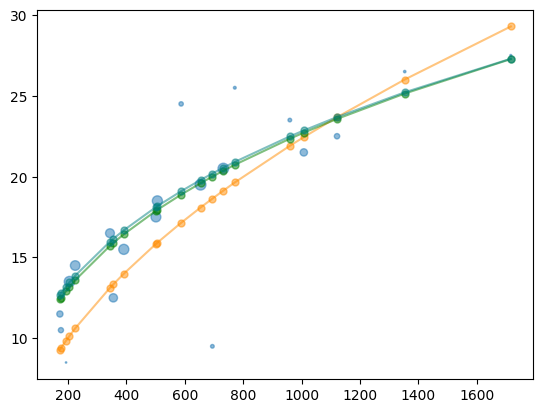

In [94]:
import pandas as pd
bleeding_factor = 0.5
bleeds = []
for area in areas:
    t_bleed = np.sqrt(area * bleeding_factor)
    bleeds.append(t_bleed)

df = pd.DataFrame({"areas":areas, "intersections":intersections, "bleeds":bleeds, "intensities":intensities})
# df = df[~df["bleeds"].isna()]
print(len(df))
# plt.scatter(areas, intersections, s = 10, alpha = 0.15)
# plt.scatter(intensities, intersections, s = 10, alpha = 0.15)
df['arin'] = (df['areas']/df['intensities']) #/1000
df['inar'] = df['intensities']/df['areas']
df['areas_div'] = df['areas']/100
minb = 8
top = 28
var = 'areas'
print(df['intersections'].min(), df['intersections'].max())
bins = np.linspace(minb,top,top - minb + 1)
bin_centers = (bins[:-1] + bins[1:]) / 2
av_var = []
av_bleeds = []
wgts = []
for jj, th_bin in enumerate(bins[1:]):
    int_rool = (intersections < bins[jj + 1]) & (intersections >= bins[jj])
    bin_mean = np.mean(df[var][int_rool])
    bin_std = np.std(df[var][int_rool])
    df[var+"_abs"] = np.abs(df[var])
    outlier_rool = df[var+"_abs"] > (bin_mean + 5*bin_std)
    # mean_area = np.median(df[var][int_rool & ~outlier_rool])
    # mean_var = np.mean(df[var][int_rool & ~outlier_rool])
    mean_var = np.mean(df[var][int_rool])
    mean_bleed = np.sqrt(mean_var * bleeding_factor)
    av_var.append(mean_var)
    av_bleeds.append(mean_bleed)
    wgts.append(len(df[int_rool]))

av_var = np.array(av_var)
av_bleeds = np.array(av_bleeds)
print(av_var)
print(df[var].max())
# print(max(intersections),min(intersections))
do_log = False
import statsmodels.api as sm
if do_log:
    av_var = np.log(av_var)
    bin_centers = np.log(bin_centers)
    av_bleeds = np.log(av_bleeds)
X_with_intercept = sm.add_constant(av_var)
wls_model = sm.WLS(bin_centers, X_with_intercept, weights=wgts)
results = wls_model.fit()
print(results.summary())
intercept = results.params[0]
slope = results.params[1]
print(f"\nIntercept: {intercept:.4f}")
print(f"Slope: {slope:.4f}")
mid_x = av_var.mean()
line_pt = mid_x*slope + intercept

# X_with_intercept_bleeds = sm.add_constant(df[var])
# wls_model_b = sm.WLS(bleeds, X_with_intercept_bleeds)
# results_b = wls_model_b.fit()
# intercept_b = results_b.params[0]
# slope_b = results_b.params[1]
# line_pt_b = mid_x*slope_b + intercept_b

# plt.scatter(df[var], df['intersections'], s = 10, alpha = 0.15)
plt.scatter(av_var, bin_centers, s = wgts, alpha = 0.5)
# plt.axline((mid_x,line_pt), slope = slope)
# plt.axline((mid_x,line_pt+0.02), slope = 1/3, linestyle = "--", color = "red")
# plt.axline((mid_x,line_pt_b), slope = slope_b)
# plt.scatter(av_var, av_bleeds, s = 5, alpha = 0.5, linestyle='-')

sort_indices = np.argsort(av_var)
x_sorted = av_var[sort_indices]
y_sorted = av_bleeds[sort_indices]
plt.plot(x_sorted, y_sorted, marker = "o", markersize = 5, alpha = 0.5, linestyle='-', color = "darkorange")

y_rd_model = 2.12*np.pow(x_sorted,0.343)
plt.plot(x_sorted, y_rd_model, marker = "o", markersize = 5, alpha = 0.5, linestyle='-', color = "green")
y_rd_model = 1.14*2*np.pow(x_sorted,1/3)
plt.plot(x_sorted, y_rd_model, marker = "o", markersize = 5, alpha = 0.5, linestyle='-', color = "teal")

realistic_arin = 16000
# plt.scatter(realistic_arin, realistic_arin*slope+intercept)
# plt.hist(intersections, bins = np.linspace(min,top,top - min + 1), weights = areas)
# plt.xscale("log")
# plt.xlim(0,1100)
# plt.ylim(5,25)
plt.show()